# 01 · EDA y comprensión de los datos — Bike Sharing Demand

**Responsable:** Joan · **Plan:** `project_plan_crisp_dm.md` §3 (comprensión) y §4 (preparación) · **Dataset:** `data/raw/hour.csv`

**Objetivo:** documentar la calidad del dato, la dinámica de la demanda y las decisiones de preparación que se derivan, y mostrar paso a paso cómo `src/` transforma los datos.

**Regla de este notebook:** todo análisis que alimenta una decisión usa **solo train** (2011-01-01 a 2012-06-30). El test (jul–dic 2012) no se usa para decidir nada. Las únicas lecturas sobre la serie completa son *conteos de estructura* (horas ausentes, filas con valores imposibles) que verifican afirmaciones del plan y no entran a ningún modelo.

**Estado de las afirmaciones:** se indica si cada afirmación está verificada con el código de este notebook, es una hipótesis o está pendiente.


## 1) Preparación del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# El notebook puede abrirse desde la raíz o desde notebooks/: buscamos la raíz del repo
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py hacia arriba desde el directorio actual")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, crear_variables

sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

print("Raíz del repo:", RAIZ)
print("numpy", np.__version__, "| pandas", pd.__version__)

Raíz del repo: D:\PrograUniversidad\MachineLearning\bike-sharing-ml
numpy 2.5.3 | pandas 3.0.5


### Punto de control 1: configuración

In [2]:
assert RANDOM_STATE == 42 and CONFIG["random_state"] == 42
assert CONFIG["ruta_hour"].exists(), "No existe data/raw/hour.csv"
assert set(CONFIG["features"]) == {"tendencia", "windspeed_cero", "hum_cero", "hora"}
print(" Configuración cargada. Valores PROVISIONALES de ablación:", CONFIG["features"])

 Configuración cargada. Valores PROVISIONALES de ablación: {'tendencia': 'yr', 'windspeed_cero': 'dejar', 'hum_cero': 'mediana', 'hora': 'entero'}


## 2) Carga, ficha técnica y reindexación a la serie horaria continua

`hour.csv` trae solo las horas con registro. `load_data()` reindexa a las 17 544 horas posibles (2011-01-01 00:00 a 2012-12-31 23:00) y deja el target en NaN en las horas ausentes; **no se inventa**. Antes de usarla, miramos el archivo crudo.

In [3]:
raw = pd.read_csv(CONFIG["ruta_hour"], parse_dates=["dteday"])
print("Archivo crudo:", raw.shape)
print("Rango de fechas:", raw["dteday"].min().date(), "->", raw["dteday"].max().date(), "| días distintos:", raw["dteday"].nunique())
print("Valores nulos en el archivo crudo:", int(raw.isna().sum().sum()))
display(raw.dtypes.to_frame("dtype").T)
display(raw.head(3))

Archivo crudo: (17379, 17)
Rango de fechas: 2011-01-01 -> 2012-12-31 | días distintos: 731
Valores nulos en el archivo crudo: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
dtype,int64,datetime64[us],int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


In [4]:
df = load_data()
print("Tras load_data():", df.shape, "| índice:", df.index.min(), "->", df.index.max())
print("Horas con target NaN (ausentes):", int(df["cnt"].isna().sum()))
display(df.loc["2011-01-01 00:00":"2011-01-01 03:00", ["dteday", "hr", "season", "workingday", "weathersit", "temp", "cnt"]])
# Una hora ausente: el calendario se reconstruye, el clima y el target quedan NaN
ejemplo = df[df["cnt"].isna()].head(2)
display(ejemplo[["dteday", "hr", "season", "workingday", "weathersit", "temp", "cnt"]])

Tras load_data(): (17544, 17) | índice: 2011-01-01 00:00:00 -> 2012-12-31 23:00:00
Horas con target NaN (ausentes): 165


,dteday,hr,season,workingday,weathersit,temp,cnt
fecha_hora,,,,,,,
2011-01-01 00:00:00,2011-01-01,0,1,0,1.0,0.24,16.0
2011-01-01 01:00:00,2011-01-01,1,1,0,1.0,0.22,40.0
2011-01-01 02:00:00,2011-01-01,2,1,0,1.0,0.22,32.0
2011-01-01 03:00:00,2011-01-01,3,1,0,1.0,0.24,13.0


,dteday,hr,season,workingday,weathersit,temp,cnt
fecha_hora,,,,,,,
2011-01-02 05:00:00,2011-01-02,5,1,0,NaN,NaN,NaN
2011-01-03 02:00:00,2011-01-03,2,1,1,NaN,NaN,NaN


### Punto de control 2: forma de los datos

In [5]:
assert raw.shape == (17379, 17), raw.shape
assert raw["dteday"].nunique() == 731
assert raw.isna().sum().sum() == 0
assert df.shape == (17544, 17) and len(df) == CONFIG["n_horas"]
assert df.index.is_unique and df.index.is_monotonic_increasing
assert (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "la serie no es horaria continua"
assert df["cnt"].isna().sum() == 165
assert df[["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday"]].isna().sum().sum() == 0, "calendario incompleto"
# El calendario reconstruido es coherente con el índice
assert (df.index.hour == df["hr"]).all() and (df.index.month == df["mnth"]).all() and (df.index.year - 2011 == df["yr"]).all()
assert ((df.index.dayofweek + 1) % 7 == df["weekday"]).all()
print(" 17 379 filas originales -> 17 544 horas continuas, 165 ausentes, calendario completo.")

 17 379 filas originales -> 17 544 horas continuas, 165 ausentes, calendario completo.


**Interpretación.** El archivo crudo tiene 17 379 filas y 731 días sin nulos, pero una serie horaria de 2 años debería tener 17 544 filas: faltan **165 horas** (0.94 %). Un `shift` o una media móvil sobre el archivo crudo mezclaría horas que no son consecutivas, por eso reindexamos *antes* de cualquier otra cosa. En las horas ausentes el calendario se reconstruye (se conoce con certeza) y el clima y el target quedan en NaN: no se inventa información. Esas filas no entran a `fit` ni a las métricas (`separar_xy` las descarta).

## 3) Partición temporal

Train hasta 2012-06-30 y test desde 2012-07-01 (hold-out de una sola evaluación). A partir de aquí **todas las decisiones usan `tr`**.

In [6]:
train, test = temporal_split(df)
tr = train  # único conjunto que se analiza a partir de ahora
print(f"Train: {tr.index.min()} -> {tr.index.max()} | {len(tr):,} horas ({len(tr)/len(df):.1%})")
print(f"Test : {test.index.min()} -> {test.index.max()} | {len(test):,} horas ({len(test)/len(df):.1%})")
print("Horas ausentes en train:", int(tr['cnt'].isna().sum()), "| en test:", int(test['cnt'].isna().sum()))

Train: 2011-01-01 00:00:00 -> 2012-06-30 23:00:00 | 13,128 horas (74.8%)
Test : 2012-07-01 00:00:00 -> 2012-12-31 23:00:00 | 4,416 horas (25.2%)
Horas ausentes en train: 125 | en test: 40


### Punto de control 3: partición sin solapamiento

In [7]:
assert tr.index.max() < test.index.min()
assert tr.index.max() == pd.Timestamp("2012-06-30 23:00") and test.index.min() == pd.Timestamp("2012-07-01 00:00")
assert len(tr) + len(test) == len(df)
assert abs(len(tr) / len(df) - 0.748) < 0.001, "la proporción de train no es ~74.8 %"
print(" Partición cronológica correcta; train =", f"{len(tr)/len(df):.1%}")

 Partición cronológica correcta; train = 74.8%


## 4) Calidad de datos (§3.2)

### 4.1 Horas faltantes
Conteo de estructura sobre la serie completa: no usa ningún valor del target.

Horas faltantes: 165 de 17544 (0.94%)
Por año: {2011: 115, 2012: 50}
Suma en las horas 2, 3 y 4: 84
Meses con más huecos: {'2011-01': 56, '2012-10': 36, '2011-02': 23, '2011-03': 14}
Número de rachas: 75 | longitud máxima: 36 | mediana: 1.0


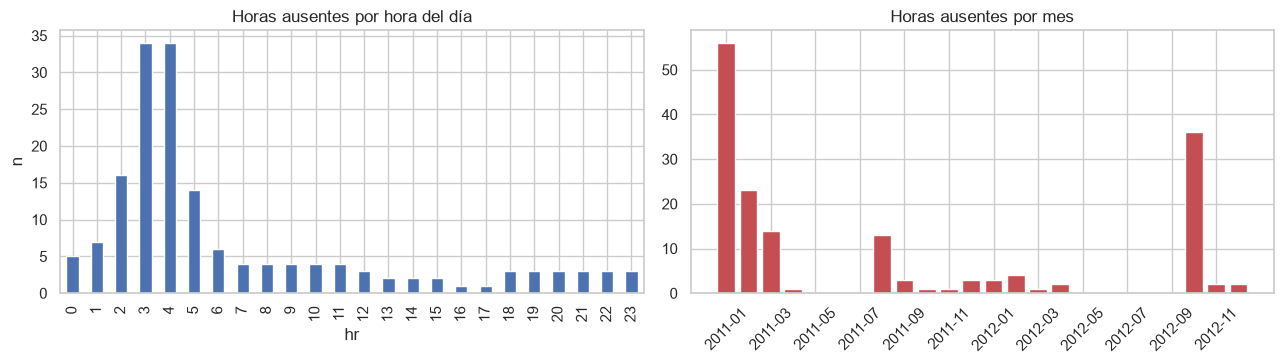

In [8]:
faltan = df[df["cnt"].isna()]
por_hora = faltan.groupby("hr").size().reindex(range(24), fill_value=0)
por_anio = faltan.groupby(faltan.index.year).size()
por_mes = faltan.groupby(faltan.index.to_period("M")).size().sort_values(ascending=False)

print(f"Horas faltantes: {len(faltan)} de {len(df)} ({len(faltan)/len(df):.2%})")
print("Por año:", por_anio.to_dict())
print("Suma en las horas 2, 3 y 4:", int(por_hora[[2, 3, 4]].sum()))
print("Meses con más huecos:", {str(k): int(v) for k, v in por_mes.head(4).items()})

# Longitud de las rachas de horas consecutivas ausentes
ausente = df["cnt"].isna()
racha_id = (ausente != ausente.shift()).cumsum()
rachas = ausente.groupby(racha_id).agg(["first", "size"])
rachas = rachas[rachas["first"]]["size"]
print("Número de rachas:", len(rachas), "| longitud máxima:", int(rachas.max()), "| mediana:", float(rachas.median()))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
por_hora.plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Horas ausentes por hora del día"); ax[0].set_xlabel("hr"); ax[0].set_ylabel("n")
mensual = faltan.groupby(faltan.index.to_period("M")).size().reindex(pd.period_range("2011-01", "2012-12", freq="M"), fill_value=0)
ax[1].bar(range(len(mensual)), mensual.to_numpy(), color="#C44E52"); ax[1].set_title("Horas ausentes por mes")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xticklabels([str(p) for p in mensual.index[::2]], rotation=45)
plt.tight_layout(); guardar(fig, "01_horas_ausentes"); plt.show()

### Punto de control 4: coincide con el plan §3.2

In [9]:
assert len(faltan) == 165 and round(len(faltan) / len(df) * 100, 2) == 0.94
assert int(por_hora[[2, 3, 4]].sum()) == 84
assert por_anio.to_dict() == {2011: 115, 2012: 50}
assert {str(k): int(v) for k, v in por_mes.head(4).items()} == {"2011-01": 56, "2012-10": 36, "2011-02": 23, "2011-03": 14}
print(" Las cifras de horas ausentes del plan §3.2 se reproducen con el código.")

 Las cifras de horas ausentes del plan §3.2 se reproducen con el código.


**Interpretación.** Los huecos no son aleatorios: se concentran en la madrugada (las horas 3 y 4 suman 34 cada una y las horas 2, 3 y 4 suman 84 de 165), que es cuando hay menos viajes, lo que sugiere Hipótesis: que una hora *sin registro* puede ser una hora *sin viajes* (el sistema no genera fila cuando nadie alquila). Esto es una hipótesis, no un hecho. Por eso no se imputa el target: imputar con la media de la hora sobreestimaría la demanda de madrugada si esas horas realmente son de demanda ~0. También hay concentración temporal: ene-2011 (56) y oct-2012 (36, mes de Sandy). La racha más larga es de 36 horas consecutivas y la mediana es 1 hora, es decir, casi todos los huecos son aislados. **Decisión:** dejar el target en NaN y excluir esas filas del ajuste y de la métrica (§4.3).

### 4.2 `windspeed = 0`
Cuántos ceros hay, qué valores vienen después del cero y si el cero aparece de forma pareja en el tiempo (análisis del conjunto train).

windspeed == 0 en el archivo crudo: 2180 de 17379 (12.5%)
Primeros valores distintos en train: [0.     0.0896 0.1045 0.1343 0.1642 0.194 ]
Salto entre 0 y el siguiente valor (x67 = km/h aprox.): 0.0896 -> 6.0
Fracción de ceros en train: 0.1176


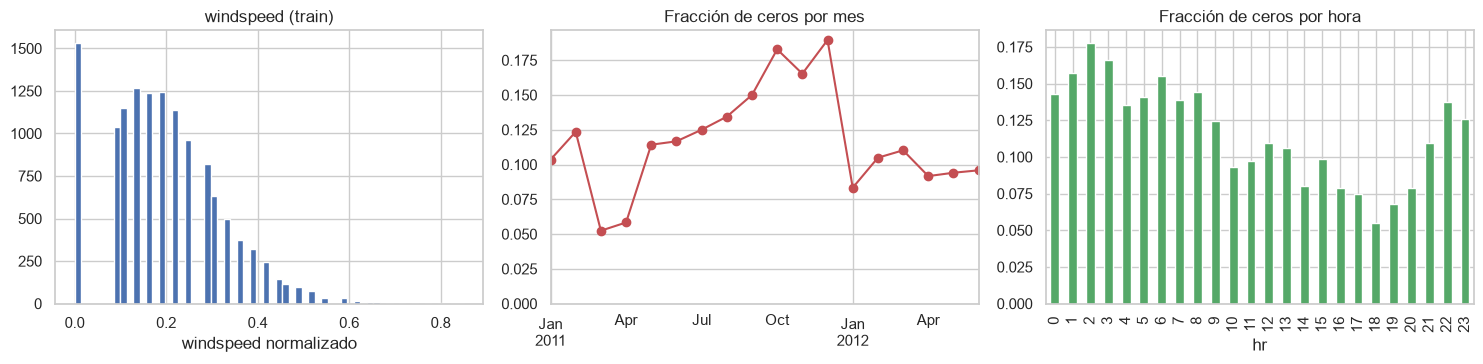

Diferencia media de cnt (viento>0 menos viento=0) por hora, resumen:


,count,mean,std,min,25%,50%,75%,max
cnt,24.0,-1.1,12.3,-22.1,-7.6,-0.4,4.0,22.8


In [10]:
n_cero_raw = int((raw["windspeed"] == 0).sum())
print(f"windspeed == 0 en el archivo crudo: {n_cero_raw} de {len(raw)} ({n_cero_raw/len(raw):.1%})")

ws = tr["windspeed"].dropna()
valores = np.sort(ws.unique())
print("Primeros valores distintos en train:", np.round(valores[:6], 4))
print("Salto entre 0 y el siguiente valor (x67 = km/h aprox.):", round(valores[1], 4), "->", round(valores[1] * 67, 2))
print("Fracción de ceros en train:", round(float((ws == 0).mean()), 4))

cero_mes = (tr["windspeed"] == 0).groupby(tr.index.to_period("M")).mean()
cero_hora = (tr["windspeed"] == 0).groupby(tr["hr"]).mean()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(ws, bins=60, color="#4C72B0"); ax[0].set_title("windspeed (train)"); ax[0].set_xlabel("windspeed normalizado")
cero_mes.plot(ax=ax[1], marker="o", color="#C44E52"); ax[1].set_title("Fracción de ceros por mes"); ax[1].set_ylim(0, None); ax[1].set_xlabel("")
cero_hora.plot.bar(ax=ax[2], color="#55A868"); ax[2].set_title("Fracción de ceros por hora"); ax[2].set_xlabel("hr")
plt.tight_layout(); guardar(fig, "02_windspeed_cero"); plt.show()

dif = tr.loc[tr["windspeed"] > 0].groupby(tr["hr"])["cnt"].mean().sub(tr.loc[tr["windspeed"] == 0].groupby(tr["hr"])["cnt"].mean())
print("Diferencia media de cnt (viento>0 menos viento=0) por hora, resumen:")
display(dif.describe().round(1).to_frame("cnt").T)

### Punto de control 5: `windspeed`

In [11]:
assert n_cero_raw == 2180 and round(n_cero_raw / len(raw) * 100, 1) == 12.5
assert (ws >= 0).all() and ws.max() <= 1.0
print(" 2 180 ceros (12.5 %) verificados en el crudo; valores en [0, 1].")

 2 180 ceros (12.5 %) verificados en el crudo; valores en [0, 1].


**Interpretación.** El 12.5 % de las filas tiene `windspeed = 0` y el histograma muestra un pico aislado en cero, separado del resto por un salto: el siguiente valor distinto de cero es 0.0896 (≈ 6 km/h al desnormalizar con ×67). Un viento realmente continuo no debería dejar un vacío entre 0 y 6 km/h, así que Hipótesis: el cero parece un valor «por debajo del umbral del sensor» o un dato no registrado, más que viento exactamente nulo. La evidencia es ambigua: los ceros son más frecuentes de madrugada (≈ 17 % a las 2:00 frente a ≈ 5 % a las 18:00), compatible con noches calmas, y su frecuencia mensual cambia de forma brusca entre dic-2011 y ene-2012, compatible con un cambio en el registro. Además, la diferencia de demanda entre horas con y sin viento es pequeña (mediana −0.4 bicicletas, con dispersión de ±12 entre horas), así que el cero no se comporta de manera claramente distinta. **Decisión:** no elegir todavía. Quedan las tres variantes de la ablación (`dejar`, `indicador`, `mediana`) y se decidirá por RMSLE de validación (Pendiente: sprint 2). Valor provisional en `CONFIG`: `dejar`.

### 4.3 `hum = 0`

Filas con hum == 0: 22 | fechas: [datetime.date(2011, 3, 10)]
Humedad mínima distinta de cero (todo el crudo): 0.08


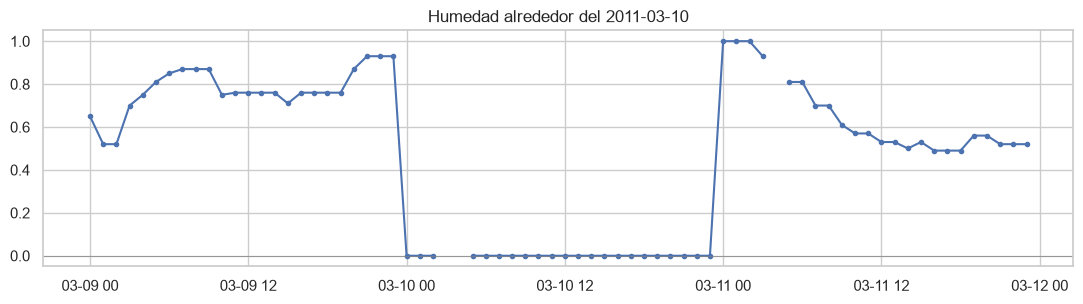

Mediana de hum (train, hum > 0): 0.62


In [12]:
hum0 = raw[raw["hum"] == 0]
print("Filas con hum == 0:", len(hum0), "| fechas:", hum0["dteday"].dt.date.unique().tolist())
print("Humedad mínima distinta de cero (todo el crudo):", raw.loc[raw["hum"] > 0, "hum"].min())
dia = df.loc["2011-03-09":"2011-03-11", "hum"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(dia.index, dia.values, marker=".", color="#4C72B0"); ax.axhline(0, color="gray", lw=0.5)
ax.set_title("Humedad alrededor del 2011-03-10"); plt.tight_layout(); guardar(fig, "03_hum_cero"); plt.show()
med_train = float(tr.loc[tr["hum"] > 0, "hum"].median())
print("Mediana de hum (train, hum > 0):", med_train)

### Punto de control 6: `hum = 0`

In [13]:
assert len(hum0) == 22
assert hum0["dteday"].nunique() == 1 and hum0["dteday"].iloc[0] == pd.Timestamp("2011-03-10")
assert hum0["dteday"].max() <= tr.index.max(), "las 22 filas con hum=0 deben estar en train"
print(" 22 filas con hum = 0, todas el 2011-03-10 y dentro de train.")

 22 filas con hum = 0, todas el 2011-03-10 y dentro de train.


**Interpretación.** Las 22 filas con humedad 0 están todas el 2011-03-10 y la humedad mínima del resto del archivo es 0.08. Una humedad de 0 % es físicamente implausible y el patrón (un solo día completo) apunta a una falla del registro, no a un fenómeno climático. Son el 0.13 % de las filas, así que el efecto esperado es pequeño. **Decisión (provisional):** convertirlas en NaN e imputar con la mediana de train (0.62), aprendida dentro del pipeline. La mediana global ignora la hora y el mes; se mantiene como punto de partida y la alternativa `dejar` queda en la ablación.

### 4.4 `weathersit = 4`

In [14]:
w4 = raw[raw["weathersit"] == 4]
print("Filas con weathersit == 4:", len(w4), f"({len(w4)/len(raw):.3%})")
display(w4[["dteday", "hr", "weathersit", "temp", "hum", "windspeed", "cnt"]])
dist = tr["weathersit"].value_counts(normalize=True).sort_index().mul(100).round(2)
print("Distribución de weathersit en train (%):", dist.to_dict())

Filas con weathersit == 4: 3 (0.017%)


,dteday,hr,weathersit,temp,hum,windspeed,cnt
585,2011-01-26,16,4,0.22,0.93,0.3284,36
8854,2012-01-09,18,4,0.20,0.86,0.0896,164
9123,2012-01-21,1,4,0.14,0.86,0.1940,23


Distribución de weathersit en train (%): {1.0: 66.1, 2.0: 25.19, 3.0: 8.68, 4.0: 0.02}


### Punto de control 7: `weathersit = 4`

In [15]:
assert len(w4) == 3
assert sorted(w4["dteday"].dt.strftime("%Y-%m-%d")) == ["2011-01-26", "2012-01-09", "2012-01-21"]
assert (pd.to_datetime(w4["dteday"]) <= pd.Timestamp("2012-06-30")).all(), "las 3 filas deben estar en train"
print(" 3 filas con weathersit = 4, las tres en train: se fusionan con 3.")

 3 filas con weathersit = 4, las tres en train: se fusionan con 3.


**Interpretación.** `weathersit = 4` aparece solo 3 veces (0.017 %), las tres en invierno y dentro de train. Con tan pocas filas ningún modelo puede aprender un efecto propio de esa categoría y un One-Hot generaría una columna casi vacía. **Decisión:** fusionar con la categoría 3 (clima adverso). En train, el clima 1 es el 66.1 % de las filas, el 2 el 25.2 % y el 3 el 8.7 % antes de fusionar.

### 4.5 `temp` vs `atemp` y multicolinealidad
Calculamos la correlación y el **VIF real** (no se afirma su reducción sin medirlo). VIF de cada variable = diagonal de la inversa de la matriz de correlación.

Correlación temp-atemp (crudo completo): 0.9877
Correlación temp-atemp (train): 0.9918


,VIF original,VIF con temp_c y temp_diff
temp,68.65,NaN
atemp,68.78,NaN
hum,1.10,1.10
windspeed,1.21,1.21
temp_c,NaN,1.40
temp_diff,NaN,1.52


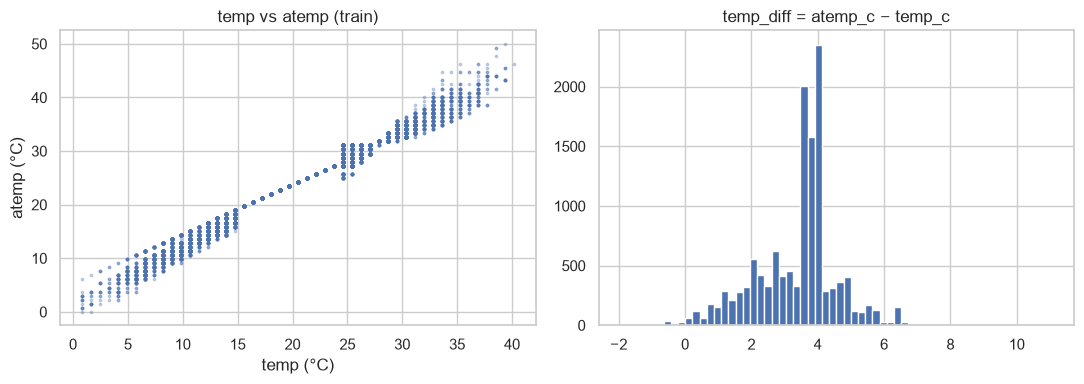

Resumen de temp_diff (°C):


,count,mean,std,min,25%,50%,75%,max
temp_diff,13003.0,3.39,1.27,-1.95,2.66,3.68,4.0,11.08


In [16]:
def vif(frame):
    corr = frame.corr().to_numpy()
    return pd.Series(np.diag(np.linalg.inv(corr)), index=frame.columns)

base = tr[["temp", "atemp", "hum", "windspeed"]].dropna()
print("Correlación temp-atemp (crudo completo):", round(raw["temp"].corr(raw["atemp"]), 4))
print("Correlación temp-atemp (train):", round(base["temp"].corr(base["atemp"]), 4))

original = base.copy()
nuevo = pd.DataFrame({"temp_c": base["temp"] * 41, "temp_diff": base["atemp"] * 50 - base["temp"] * 41,
                      "hum": base["hum"], "windspeed": base["windspeed"]})
tabla_vif = pd.concat([vif(original).rename("VIF original"), vif(nuevo).rename("VIF con temp_c y temp_diff")], axis=1)
display(tabla_vif.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(base["temp"] * 41, base["atemp"] * 50, s=3, alpha=0.3); ax[0].set_xlabel("temp (°C)"); ax[0].set_ylabel("atemp (°C)"); ax[0].set_title("temp vs atemp (train)")
ax[1].hist(nuevo["temp_diff"], bins=60, color="#4C72B0"); ax[1].set_title("temp_diff = atemp_c − temp_c")
plt.tight_layout(); guardar(fig, "04_temp_atemp"); plt.show()
print("Resumen de temp_diff (°C):"); display(nuevo["temp_diff"].describe().round(2).to_frame("temp_diff").T)

### Punto de control 8: colinealidad

In [17]:
assert abs(raw["temp"].corr(raw["atemp"]) - 0.9877) < 5e-4, "la correlación del plan (0.9877) no se reproduce"
assert (vif(nuevo)["temp_c"] < vif(original)[["temp", "atemp"]].max()), "temp_c/temp_diff no reducen el VIF máximo"
print(" r(temp, atemp) = 0.9877 reproducida; VIF medido antes y después de la transformación.")

 r(temp, atemp) = 0.9877 reproducida; VIF medido antes y después de la transformación.


**Interpretación.** `temp` y `atemp` tienen correlación 0.9877 en el archivo completo (0.9918 en train) y un VIF cercano a 69 cada una: son casi la misma información y en un modelo lineal inflarían la varianza de los coeficientes. Al representar el par como `temp_c` (temperatura en °C) y `temp_diff = atemp_c − temp_c` (diferencia entre sensación y temperatura), el VIF baja a 1.40 y 1.52. No se pierde información, ya que `atemp` se recupera sumando ambas; lo que cambia es que ahora la segunda variable mide algo distinto (cuánto se aleja la sensación de la temperatura, 3.4 °C de media en train). La reducción del VIF queda **medida**, no supuesta.

## 5) Distribución del target (§3.4 punto 2)
Justificamos `log1p(cnt)` con la asimetría medida en train.

       count   mean    std  min   25%    50%    75%    max
cnt  13003.0  167.7  160.8  1.0  35.0  124.0  246.0  957.0

Asimetría de cnt: 1.291 | asimetría de log1p(cnt): -0.812
Mínimo de cnt en train: 1 | ceros: 0


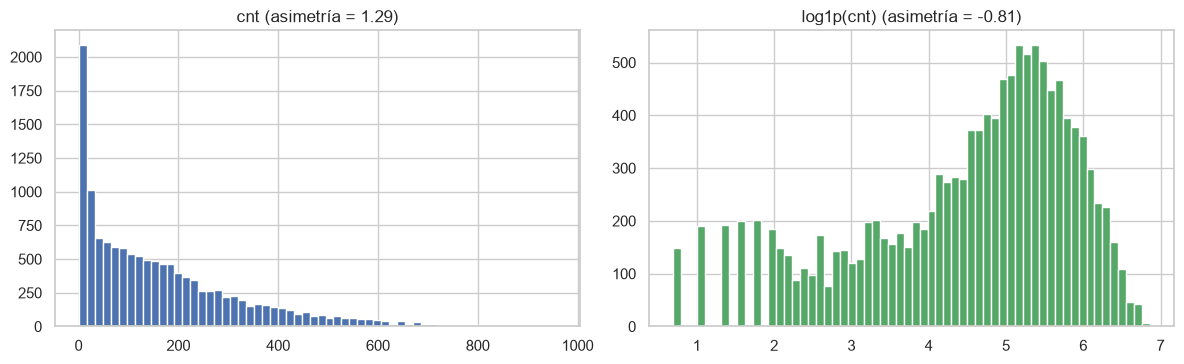

In [18]:
y_tr = tr["cnt"].dropna()
sk_raw, sk_log = float(stats.skew(y_tr)), float(stats.skew(np.log1p(y_tr)))
print(y_tr.describe().round(1).to_frame("cnt").T.to_string())
print(f"\nAsimetría de cnt: {sk_raw:.3f} | asimetría de log1p(cnt): {sk_log:.3f}")
print("Mínimo de cnt en train:", int(y_tr.min()), "| ceros:", int((y_tr == 0).sum()))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(y_tr, bins=60, color="#4C72B0"); ax[0].set_title(f"cnt (asimetría = {sk_raw:.2f})")
ax[1].hist(np.log1p(y_tr), bins=60, color="#55A868"); ax[1].set_title(f"log1p(cnt) (asimetría = {sk_log:.2f})")
plt.tight_layout(); guardar(fig, "05_target"); plt.show()

### Punto de control 9: target

In [19]:
assert y_tr.notna().all() and (y_tr >= 0).all()
assert sk_raw > 0, "se esperaba asimetría positiva"
assert abs(sk_log) < abs(sk_raw), "log1p no reduce la asimetría"
print(" El target tiene asimetría positiva y log1p la reduce en valor absoluto.")

 El target tiene asimetría positiva y log1p la reduce en valor absoluto.


**Interpretación.** `cnt` en train tiene asimetría positiva (1.29): la mediana (124) está bien por debajo de la media (167.7) y hay una cola larga hasta 957. Con `log1p` la asimetría pasa a −0.81: se reduce en valor absoluto, pero la cola se invierte hacia la izquierda (hay muchas horas de madrugada con pocas bicicletas), de modo que **no queda simétrica**. La justificación principal de `log1p` no es normalizar sino **alinear el entrenamiento con la métrica**: minimizar el error cuadrático en `log1p(cnt)` equivale a minimizar el RMSLE. El mínimo es 1, no hay ceros, así que `log1p` no tiene problemas de dominio.

## 6) Dinámica horaria condicional (§3.4 punto 1)
Perfil de demanda por hora, separado por tipo de día, y contraste entre usuarios `casual` y `registered`. **Solo para EDA:** `casual` y `registered` no entran como variables de entrada.

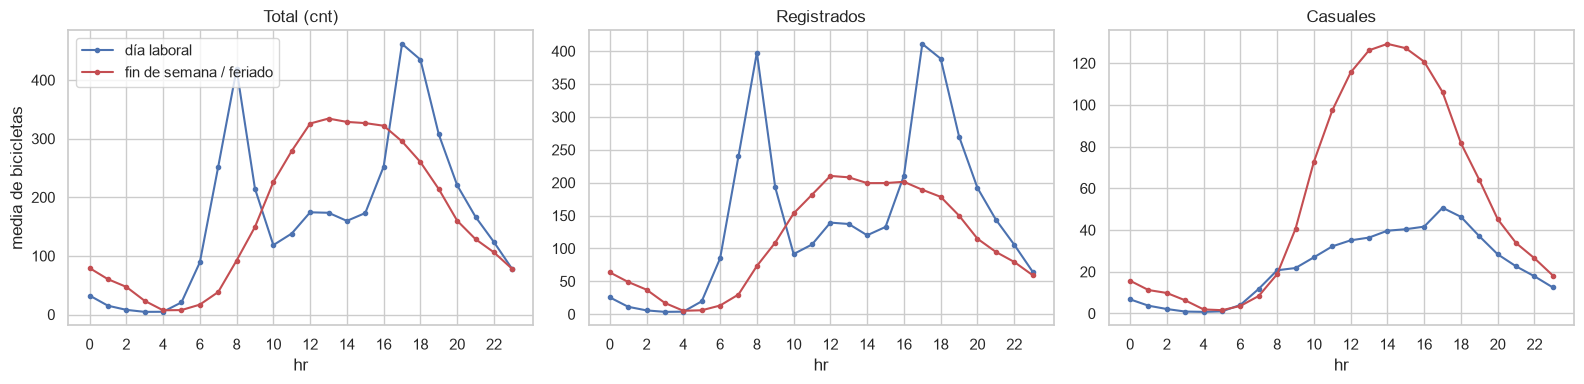

Día laboral: pico de la mañana a las 8:00 (418) y de la tarde a las 17:00 (462)
Fin de semana/feriado: pico máximo a las 13:00 (334)
Proporción de casuales por tipo de día: {0: 0.328, 1: 0.134}


In [20]:
perfil = tr.groupby(["workingday", "hr"])[["cnt", "casual", "registered"]].mean()

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for a, col, titulo in zip(ax, ["cnt", "registered", "casual"], ["Total (cnt)", "Registrados", "Casuales"]):
    for wd, etiqueta, color in [(1, "día laboral", "#4C72B0"), (0, "fin de semana / feriado", "#C44E52")]:
        a.plot(perfil.loc[wd].index, perfil.loc[wd, col], marker="o", ms=3, label=etiqueta, color=color)
    a.set_title(titulo); a.set_xlabel("hr"); a.set_xticks(range(0, 24, 2))
ax[0].set_ylabel("media de bicicletas"); ax[0].legend()
plt.tight_layout(); guardar(fig, "06_perfil_horario"); plt.show()

lab = perfil.loc[1, "cnt"]
pico_manana = int(lab.loc[5:11].idxmax()); pico_tarde = int(lab.loc[14:21].idxmax())
pico_finde = int(perfil.loc[0, "cnt"].idxmax())
print(f"Día laboral: pico de la mañana a las {pico_manana}:00 ({lab[pico_manana]:.0f}) y de la tarde a las {pico_tarde}:00 ({lab[pico_tarde]:.0f})")
print(f"Fin de semana/feriado: pico máximo a las {pico_finde}:00 ({perfil.loc[0,'cnt'][pico_finde]:.0f})")
reg_share = tr.groupby("workingday")[["casual", "registered"]].sum()
print("Proporción de casuales por tipo de día:", (reg_share['casual'] / reg_share.sum(axis=1)).round(3).to_dict())

### Punto de control 10: perfil horario

In [21]:
assert perfil.shape[0] == 48, "debe haber 24 horas x 2 tipos de día"
assert 7 <= pico_manana <= 9 and 16 <= pico_tarde <= 18, (pico_manana, pico_tarde)
assert 10 <= pico_finde <= 15, pico_finde
print(" Picos laborales a ~08:00 y ~17:00-18:00; fin de semana con un pico central.")

 Picos laborales a ~08:00 y ~17:00-18:00; fin de semana con un pico central.


**Interpretación.** La demanda depende de la hora **de forma distinta según el tipo de día**. En días laborales hay dos picos nítidos, a las 8:00 (≈ 418 bicicletas) y a las 17:00 (≈ 462), el patrón de ida y vuelta al trabajo. En fines de semana y feriados hay una sola campana ancha con máximo a las 13:00 (≈ 334). El contraste casual/registrado lo refuerza: los registrados reproducen los picos laborales, mientras que los casuales dominan el fin de semana (el 32.8 % de los viajes de esos días frente al 13.4 % en días laborales). Un modelo que use `hr` y `workingday` por separado debe aprender esa interacción; por eso se crea la categoría combinada `hr_workingday` (48 niveles, p. ej. `"17_1"`) y no el producto numérico `hr * workingday`, que impondría una relación lineal que estos perfiles contradicen. `casual` y `registered` se usaron solo aquí, como descripción.

## 7) Tendencia y composición (§3.3)
El plan cita medias anuales (2011 vs 2012) que incluyen jul–dic 2012 (test). Para no usar el test comparamos **mismo semestre** (enero–junio de 2011 vs enero–junio de 2012), ambos dentro de train.

,cnt,casual,registered
anio,,,
2011,123.4,25.0,98.5
2012,215.2,40.2,174.9


Crecimiento ene-jun 2012 vs ene-jun 2011 (%): {'cnt': 74.3, 'casual': 61.0, 'registered': 77.7}
Proporción de registrados en train: 0.806
Razón 2012/2011 por mes (ene-jun): {1: 2.35, 2: 2.01, 3: 2.53, 4: 1.84, 5: 1.44, 6: 1.41}


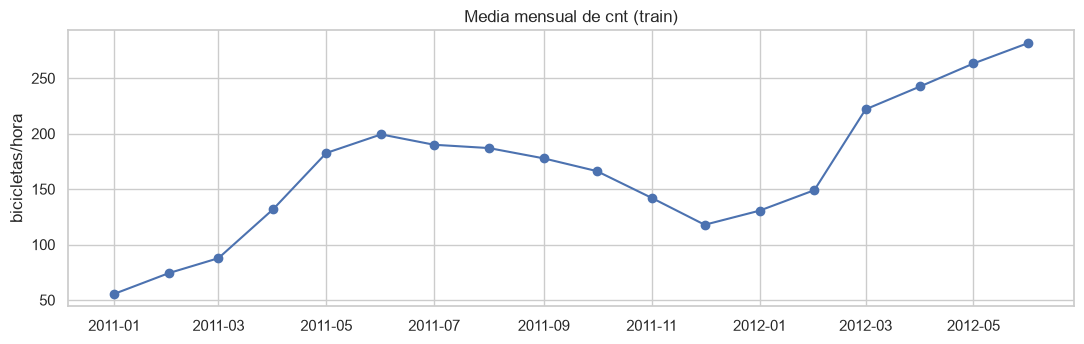

In [22]:
h1 = tr[tr["cnt"].notna()].copy()
h1["anio"] = h1.index.year
h1 = h1[h1.index.month <= 6]
res = h1.groupby("anio")[["cnt", "casual", "registered"]].agg(["mean", "sum"])
media = h1.groupby("anio")[["cnt", "casual", "registered"]].mean()
crec = (media.loc[2012] / media.loc[2011] - 1) * 100
display(media.round(1))
print("Crecimiento ene-jun 2012 vs ene-jun 2011 (%):", crec.round(1).to_dict())
print("Proporción de registrados en train:", round(float(tr['registered'].sum() / tr['cnt'].sum()), 3))

mens = tr["cnt"].groupby(tr.index.to_period("M")).mean()
mens_m = mens.copy(); mens_m.index = mens_m.index.to_timestamp()
ratio = {m: float(h1[(h1.anio == 2012) & (h1.index.month == m)]["cnt"].mean() / h1[(h1.anio == 2011) & (h1.index.month == m)]["cnt"].mean()) for m in range(1, 7)}
print("Razón 2012/2011 por mes (ene-jun):", {m: round(v, 2) for m, v in ratio.items()})

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(mens_m.index, mens_m.values, marker="o", color="#4C72B0"); ax.set_title("Media mensual de cnt (train)"); ax.set_ylabel("bicicletas/hora")
plt.tight_layout(); guardar(fig, "07_tendencia_mensual"); plt.show()

### Punto de control 11: tendencia

In [23]:
assert crec["cnt"] > 0 and crec["registered"] > 0 and crec["casual"] > 0
assert all(v > 1 for v in ratio.values()), "cada mes de 2012 debería superar al mismo mes de 2011"
assert h1.index.max() <= pd.Timestamp("2012-06-30 23:00"), "no se usó el test"
print(" Crecimiento interanual medido solo con ene-jun (train).")

 Crecimiento interanual medido solo con ene-jun (train).


**Interpretación.** Comparando el mismo semestre (ene–jun) la demanda media pasó de 123.4 a 215.2 bicicletas/hora: **+74 %** (registrados +78 %, casuales +61 %). La proporción de registrados en train es 80.6 %. El crecimiento no es uniforme: la razón 2012/2011 por mes baja de 2.35 en enero y 2.53 en marzo a 1.44 en mayo y 1.41 en junio. Hipótesis: puede deberse a que el sistema estaba arrancando en 2011 (base baja) y el efecto se diluye, pero con estos datos no puede afirmarse qué ocurrirá en jul–dic 2012. Implicaciones: (1) el nivel de 2012 es sistemáticamente mayor, así que `yr` (o una variable de tendencia) debe aportar información; (2) los árboles no extrapolan, y el test tiene meses sin análogo en 2012 dentro de train; (3) las cifras anuales del plan (+63 %) usan meses de test y no se recalculan aquí. Pendiente: la variante de tendencia (`yr` / `sin_yr` / `trend`) se decide por validación temporal.

## 8) Clima y estacionalidad (train)

,count,mean,median,% filas
weathersit,,,,
1.0,8595,183.4,142.0,66.1
2.0,3276,152.0,114.0,25.2
3.0,1129,93.9,56.0,8.7
4.0,3,74.3,36.0,0.0


,count,mean
tramo_temp,,
"(-10, 5]",193,48.6
"(5, 10]",1575,70.3
"(10, 15]",2552,108.5
"(15, 20]",2263,149.4
"(20, 25]",2510,190.8
"(25, 30]",2580,225.3
"(30, 45]",1330,289.7


Spearman con cnt -> temp: 0.43 | hum: -0.348 | windspeed: 0.134


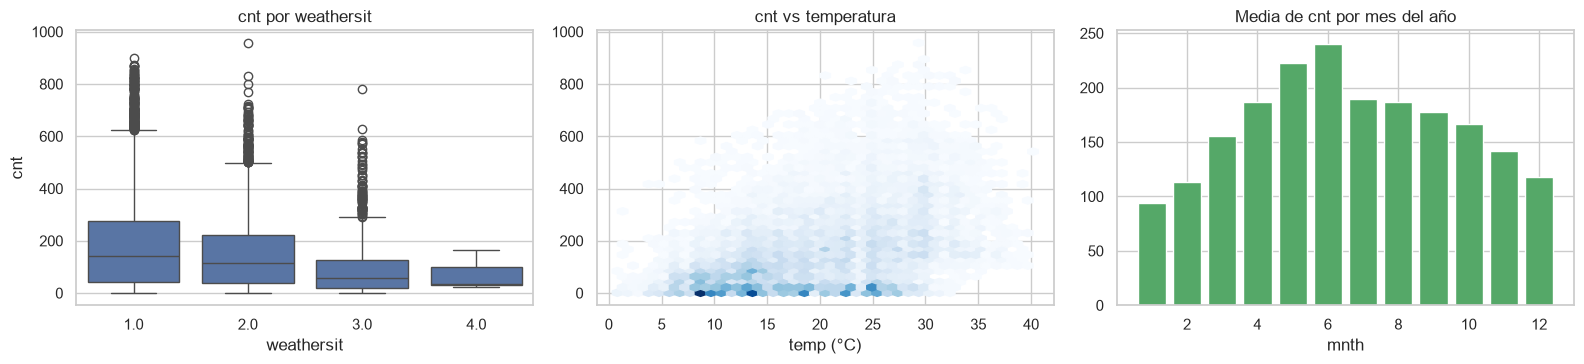

In [24]:
por_clima = tr.groupby("weathersit")["cnt"].agg(["count", "mean", "median"])
por_clima["% filas"] = por_clima["count"] / por_clima["count"].sum() * 100
display(por_clima.round(1))

tb = tr.dropna(subset=["cnt"]).copy()
tb["temp_c"] = tb["temp"] * 41
tb["tramo_temp"] = pd.cut(tb["temp_c"], bins=[-10, 5, 10, 15, 20, 25, 30, 45])
tabla_temp = tb.groupby("tramo_temp", observed=True)["cnt"].agg(["count", "mean"])
display(tabla_temp.round(1))
corr_temp = float(tb["temp_c"].corr(tb["cnt"], method="spearman"))
corr_hum = float(tb["hum"].corr(tb["cnt"], method="spearman"))
corr_ws = float(tb["windspeed"].corr(tb["cnt"], method="spearman"))
print("Spearman con cnt -> temp:", round(corr_temp, 3), "| hum:", round(corr_hum, 3), "| windspeed:", round(corr_ws, 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(data=tb, x="weathersit", y="cnt", ax=ax[0], color="#4C72B0"); ax[0].set_title("cnt por weathersit")
ax[1].hexbin(tb["temp_c"], tb["cnt"], gridsize=40, cmap="Blues", mincnt=1); ax[1].set_xlabel("temp (°C)"); ax[1].set_title("cnt vs temperatura")
mes = tb.groupby("mnth")["cnt"].mean(); ax[2].bar(mes.index, mes.values, color="#55A868"); ax[2].set_xlabel("mnth"); ax[2].set_title("Media de cnt por mes del año")
plt.tight_layout(); guardar(fig, "08_clima_estacionalidad"); plt.show()

### Punto de control 12: clima adverso

In [25]:
assert por_clima.loc[3, "mean"] < por_clima.loc[1, "mean"], "el clima 3 debería tener menos demanda que el 1"
assert corr_temp > 0
print(" Clima adverso (weathersit = 3) en train:", round(por_clima.loc[3, '% filas'], 1), "% de las filas (el 8.2 % del plan es sobre el dataset completo, no se recalcula con test).")

 Clima adverso (weathersit = 3) en train: 8.7 % de las filas (el 8.2 % del plan es sobre el dataset completo, no se recalcula con test).


**Interpretación.** La demanda baja con el clima adverso: la media por hora es 183.4 con clima 1, 152.0 con clima 2 y 93.9 con clima 3 (que es el 8.7 % de las filas de train; el 8.2 % del plan es sobre el dataset completo). La temperatura es el factor más fuerte: la media pasa de 48.6 bicicletas en el tramo ≤ 5 °C a 289.7 por encima de 30 °C, con correlación de Spearman de 0.43 con `cnt` (humedad −0.35, viento 0.13). Estas correlaciones son marginales y están mezcladas con la hora y la estación; no son efectos causales. Como el clima 3 es poco frecuente y de baja demanda, conviene reportar el RMSLE de ese subgrupo por separado en la fase de residuos (§8.2).

## 9) Evento Sandy (2012-10-29/30) — solo estructura
Cae dentro del test, así que **no se examina su demanda**; esa parte se analiza en los residuos del Sprint 4. Aquí solo se documenta cuántas horas existen en el archivo para esos días.

In [26]:
for dia in ["2012-10-28", "2012-10-29", "2012-10-30", "2012-10-31"]:
    sub = df.loc[dia]
    print(dia, "-> horas con registro:", int(sub["cnt"].notna().sum()), "de 24")

2012-10-28 -> horas con registro: 24 de 24
2012-10-29 -> horas con registro: 1 de 24
2012-10-30 -> horas con registro: 11 de 24
2012-10-31 -> horas con registro: 24 de 24


### Punto de control 13: Sandy en el test

In [27]:
assert pd.Timestamp("2012-10-29") > tr.index.max(), "Sandy debe estar fuera de train"
assert int(df.loc["2012-10-29", "cnt"].notna().sum()) == 1
print(" El 29-oct-2012 tiene 1 sola hora registrada, como indica el plan; está en el test y no se usa para decidir.")

 El 29-oct-2012 tiene 1 sola hora registrada, como indica el plan; está en el test y no se usa para decidir.


## 10) De los hallazgos a la preparación: el flujo paso a paso
Aplicamos `src/features.py` sobre train y mostramos cada transformación. `separar_xy` quita las filas con target NaN y las columnas que filtran información (`cnt`, `casual`, `registered`, `instant`).

In [28]:
X_tr, y_tr = separar_xy(tr)
print("X_tr:", X_tr.shape, "| y_tr:", y_tr.shape)
print("Columnas de X_tr:", X_tr.columns.tolist())
assert not {"cnt", "casual", "registered", "instant"} & set(X_tr.columns), "hay columnas que filtran información"
assert X_tr.index.max() <= tr.index.max()

X_tr: (13003, 13) | y_tr: (13003,)
Columnas de X_tr: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


### Paso 1 — variables derivadas sin estado (`crear_variables`)

In [29]:
cfg = CONFIG["features"]
paso1 = crear_variables(X_tr, **cfg)
print("Parámetros de ablación en uso (PROVISIONALES):", cfg)
display(paso1.head(4))

# weathersit 4 -> 3
print("weathersit antes :", X_tr["weathersit"].value_counts().sort_index().to_dict())
print("weathersit después:", paso1["weathersit"].value_counts().sort_index().to_dict())
# Desnormalización y temp_diff
assert np.allclose(paso1["temp_c"], X_tr["temp"] * 41)
assert np.allclose(paso1["temp_diff"], X_tr["atemp"] * 50 - X_tr["temp"] * 41)
# Categoría combinada hora x tipo de día
print("Ejemplos de hr_workingday:", paso1["hr_workingday"].sample(5, random_state=RANDOM_STATE).tolist(), "| categorías:", paso1["hr_workingday"].nunique())
assert paso1["hr_workingday"].nunique() == 48
# hum == 0 pasa a NaN (se imputa en el paso 2 con la mediana de train)
print("hum == 0 antes:", int((X_tr['hum'] == 0).sum()), "| NaN en hum tras el paso 1:", int(paso1['hum'].isna().sum()))
assert paso1["hum"].isna().sum() == (X_tr["hum"] == 0).sum()
assert not {"atemp", "temp", "dteday"} & set(paso1.columns)

Parámetros de ablación en uso (PROVISIONALES): {'tendencia': 'yr', 'windspeed_cero': 'dejar', 'hum_cero': 'mediana', 'hora': 'entero'}


,season,mnth,holiday,weekday,workingday,weathersit,temp_c,temp_diff,hum,windspeed,hr,hr_workingday,yr
fecha_hora,,,,,,,,,,,,,
2011-01-01 00:00:00,1,1,0,6,0,1,9.84,4.555,0.81,0.0,0,0_0,0
2011-01-01 01:00:00,1,1,0,6,0,1,9.02,4.615,0.80,0.0,1,1_0,0
2011-01-01 02:00:00,1,1,0,6,0,1,9.02,4.615,0.80,0.0,2,2_0,0
2011-01-01 03:00:00,1,1,0,6,0,1,9.84,4.555,0.75,0.0,3,3_0,0


weathersit antes : {1.0: 8595, 2.0: 3276, 3.0: 1129, 4.0: 3}
weathersit después: {1: 8595, 2: 3276, 3: 1132}
Ejemplos de hr_workingday: ['5_1', '16_1', '12_1', '20_1', '7_1'] | categorías: 48
hum == 0 antes: 22 | NaN en hum tras el paso 1: 22


### Paso 2 — One-Hot, imputación y escalado dentro del `ColumnTransformer` (se ajusta solo con train)

In [30]:
prep = build_preprocessor()
Z_tr = prep.fit_transform(X_tr)
print("Matriz transformada:", Z_tr.shape)
print("Columnas no One-Hot:", [c for c in Z_tr.columns if not c.startswith(("season_", "weathersit_", "hr_workingday_"))])
imputer = prep.named_steps["columnas"].named_transformers_["num_imp"].named_steps["imputer"]
print("Mediana de hum aprendida en train:", float(imputer.statistics_[0]), "| calculada a mano:", med_train)
assert np.isclose(imputer.statistics_[0], med_train)
assert np.isfinite(Z_tr.to_numpy()).all()
assert Z_tr.index.equals(X_tr.index)
assert not {"casual", "registered", "instant", "dteday", "cnt", "temp", "atemp"} & set(Z_tr.columns)
display(Z_tr.iloc[:3, -10:])

Matriz transformada: (13003, 65)
Columnas no One-Hot: ['mnth', 'holiday', 'weekday', 'workingday', 'temp_c', 'temp_diff', 'hr', 'yr', 'windspeed', 'hum']
Mediana de hum aprendida en train: 0.62 | calculada a mano: 0.62


,mnth,holiday,weekday,workingday,temp_c,temp_diff,hr,yr,windspeed,hum
fecha_hora,,,,,,,,,,
2011-01-01 00:00:00,1,0,6,0,9.84,4.555,0,0,0.0,0.81
2011-01-01 01:00:00,1,0,6,0,9.02,4.615,1,0,0.0,0.80
2011-01-01 02:00:00,1,0,6,0,9.02,4.615,2,0,0.0,0.80


### Paso 3 — las ablaciones cambian la matriz, no el contrato
Cada parámetro de ablación genera una variante distinta con la misma interfaz. La elección final se hará con el RMSLE de validación temporal (Pendiente: sprint 2); aquí solo se comprueba que todas funcionan.

In [31]:
variantes = {
    "base (CONFIG)": {},
    "tendencia='sin_yr'": {"tendencia": "sin_yr"},
    "tendencia='trend'": {"tendencia": "trend"},
    "windspeed_cero='indicador'": {"windspeed_cero": "indicador"},
    "windspeed_cero='mediana'": {"windspeed_cero": "mediana"},
    "hum_cero='dejar'": {"hum_cero": "dejar"},
    "escalar=True (lineales)": {"escalar": True},
}
filas = []
for nombre, kw in variantes.items():
    Z = build_preprocessor(**kw).fit_transform(X_tr)
    assert np.isfinite(Z.to_numpy()).all() and len(Z) == len(X_tr)
    filas.append({"variante": nombre, "n_columnas": Z.shape[1], "min_hum": round(float(Z["hum"].min()), 3) if "hum" in Z else None})
display(pd.DataFrame(filas))

,variante,n_columnas,min_hum
0,base (CONFIG),65,0.080
1,tendencia='sin_yr',64,0.080
2,tendencia='trend',65,0.080
3,windspeed_cero='indicador',66,0.080
4,windspeed_cero='mediana',65,0.080
5,hum_cero='dejar',65,0.000
6,escalar=True (lineales),65,-2.749


### Punto de control 14: el preprocesador no usa el test

In [32]:
X_te, y_te = separar_xy(test)
Z_te = prep.transform(X_te)   # solo transform: nada se reajusta con el test
assert Z_te.shape[1] == Z_tr.shape[1] and list(Z_te.columns) == list(Z_tr.columns)
assert np.isclose(imputer.statistics_[0], med_train), "el imputador cambió tras ver el test"
del X_te, y_te, Z_te
print(" Transformar el test no modifica los parámetros aprendidos en train.")

 Transformar el test no modifica los parámetros aprendidos en train.

## 11) Artefactos de `data/processed/`
Se guardan las dos particiones (carpeta ignorada por git; se regeneran con este notebook).

In [33]:
CONFIG["dir_processed"].mkdir(parents=True, exist_ok=True)
tr.to_csv(CONFIG["dir_processed"] / "train.csv")
test.to_csv(CONFIG["dir_processed"] / "test.csv")
chk = pd.read_csv(CONFIG["dir_processed"] / "train.csv", index_col=0, parse_dates=True)
assert chk.shape == tr.shape
print(" Guardados train.csv", tr.shape, "y test.csv", test.shape)

 Guardados train.csv (13128, 17) y test.csv (4416, 17)


## 12) Resumen de hallazgos y decisiones

| Hallazgo (train, salvo que se indique) | Evidencia | Decisión de preparación |
| :--- | :--- | :--- |
| 165 horas ausentes (0.94 %), concentradas de madrugada | 125 en train, 84 en las horas 2–4 | Reindexar a 17 544 horas; target NaN y fuera del ajuste y de la métrica |
| `windspeed = 0` en 12.5 % | Salto 0 → 0.0896; frecuencia dependiente de hora y mes | Pendiente: ablación `dejar` / `indicador` / `mediana` (provisional: `dejar`) |
| `hum = 0` en 22 filas (2011-03-10) | Implausible, un solo día | Imputar con mediana de train (provisional); ablación contra `dejar` |
| `weathersit = 4` en 3 filas | 0.017 % | Fusionar con 3 |
| `temp`–`atemp` con r = 0.9877 | VIF 68.65 / 68.78 → 1.40 / 1.52 | `temp_c` y `temp_diff` |
| Target asimétrico (1.29) | log1p: −0.81 | Entrenar sobre `log1p(cnt)`; revertir con `expm1` |
| Perfil horario depende del tipo de día | Picos 8:00 y 17:00 vs. campana a las 13:00 | Categoría `hr_workingday` (One-Hot) |
| Crecimiento ene–jun: +74 % | Razón mensual de 2.5 a 1.4 | Pendiente: ablación de tendencia (provisional: `yr`); riesgo para árboles |
| Clima adverso: 93.9 vs 183.4 bicis/hora | 8.7 % de las filas | Reportar RMSLE del subgrupo `weathersit >= 3` |
| Sandy (29–30 oct 2012) | 1 hora el 29, 11 el 30 | Solo estructura; análisis en residuos (Sprint 4) |

**Aviso para la validación (relevante para Sprint 2):** con 5 folds de `test_size=1460` las ventanas de validación cubren del 2011-08-31 al 2012-06-30, es decir, de fines de verano de 2011 a junio de 2012; **ningún fold valida en julio ni agosto**, los meses de mayor demanda. El test (jul–dic 2012) sí los incluye.